# GitHub activity of @cboulanger per quarter, 2017 to today

Contrasts quarterly GitHub contributions before 2025 with 2025 onward (when I started coding with Claude), to illustrate the effect of agentic coding.

**Data source.** By default the notebook reads the public contribution calendar
(`https://github.com/users/<login>/contributions?from=YYYY-01-01&to=YYYY-12-31`), which needs no token.
It holds a count per day, which the notebook sums into quarters. These counts are *contributions*
(commits, pull requests, issues, reviews, new repos); private contributions are included only if
"Private contributions" is enabled on the profile.

If the environment variable `GITHUB_TOKEN` is set (a personal token with `read:user`), the notebook instead
asks the GraphQL API for `totalCommitContributions` per quarter, i.e. commits only, plus private
contributions the token can see. Run with `USE_CACHE=1` to skip the network and redraw from `contributions-quarterly.csv`.

In [1]:
import os, re, csv, datetime as dt
import requests
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

LOGIN = "cboulanger"
FIRST_YEAR, SPLIT_YEAR = 2017, 2025          # before vs. after starting to use Claude
TODAY = dt.date.today()
USE_CACHE = os.environ.get("USE_CACHE") == "1"   # reuse the CSV instead of fetching
CSV_PATH = "contributions-quarterly.csv"
TOKEN = os.environ.get("GITHUB_TOKEN")
QUARTERS = [(y, q) for y in range(FIRST_YEAR, TODAY.year + 1) for q in range(1, 5)
            if dt.date(y, 3 * q - 2, 1) <= TODAY]

In [2]:
def calendar_days(year):
    """Daily counts {date: n} from the public contribution calendar of one year."""
    url = f"https://github.com/users/{LOGIN}/contributions?from={year}-01-01&to={year}-12-31"
    html = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=30).text
    dates = dict(re.findall(r'data-date="(\d{4}-\d\d-\d\d)"[^>]*\bid="([^"]+)"', html))
    ids = {v: k for k, v in dates.items()}
    days = {}
    for cell_id, text in re.findall(r'<tool-tip[^>]*\bfor="([^"]+)"[^>]*>([^<]*)</tool-tip>', html):
        m = re.match(r"\s*(\d[\d,]*) contributions?", text)
        if cell_id in ids:
            days[ids[cell_id]] = int(m.group(1).replace(",", "")) if m else 0
    total = re.search(r"([\d,]+)\s+contributions?\s+in\s+" + str(year), html)
    if total:  # sanity check against the yearly total GitHub prints above the calendar
        assert sum(n for d, n in days.items() if d.startswith(str(year))) == int(total.group(1).replace(",", "")), year
    return days

def calendar_quarter(year, q, _cache={}):
    if year not in _cache:
        _cache[year] = calendar_days(year)
    return sum(n for d, n in _cache[year].items()
               if d.startswith(str(year)) and (int(d[5:7]) - 1) // 3 + 1 == q)

def graphql_quarter(year, q):
    """Commits only (needs GITHUB_TOKEN); restricted = private contributions not otherwise visible."""
    start = dt.datetime(year, 3 * q - 2, 1)
    end = dt.datetime(year + (q == 4), 1 if q == 4 else 3 * q + 1, 1) - dt.timedelta(seconds=1)
    query = """query($login:String!,$from:DateTime!,$to:DateTime!){
      user(login:$login){contributionsCollection(from:$from,to:$to){
        totalCommitContributions restrictedContributionsCount}}}"""
    v = {"login": LOGIN, "from": start.isoformat() + "Z", "to": end.isoformat() + "Z"}
    r = requests.post("https://api.github.com/graphql", json={"query": query, "variables": v},
                      headers={"Authorization": f"bearer {TOKEN}"}, timeout=30)
    c = r.json()["data"]["user"]["contributionsCollection"]
    return c["totalCommitContributions"] + c["restrictedContributionsCount"]

if USE_CACHE and os.path.exists(CSV_PATH):
    with open(CSV_PATH) as f:
        recs = list(csv.DictReader(f))
    rows = [(int(r["year"]), int(r["quarter"]), int(r["count"])) for r in recs]
    metric, retrieved = recs[0]["metric"], dt.date.fromisoformat(recs[0]["retrieved"])
else:
    fetch, metric = (graphql_quarter, "commits") if TOKEN else (calendar_quarter, "contributions")
    rows = [(y, q, fetch(y, q)) for y, q in QUARTERS]
    retrieved = TODAY
    with open(CSV_PATH, "w", newline="") as f:
        w = csv.writer(f); w.writerow(["year", "quarter", "count", "metric", "retrieved"])
        for y, q, n in rows:
            w.writerow([y, q, n, metric, TODAY.isoformat()])
rows[-6:]

[(2025, 3, 291),
 (2025, 4, 507),
 (2026, 1, 790),
 (2026, 2, 691),
 (2026, 3, 1376),
 (2026, 4, 533)]

In [3]:
# The last quarter is usually partial: it is left out of the period mean, the bar shows the real count.
last_y, last_q, _ = rows[-1]
partial = dt.date(last_y + (last_q == 4), 1 if last_q == 4 else 3 * last_q + 1, 1) > retrieved
complete = rows[:-1] if partial else rows
before = [n for y, q, n in complete if y < SPLIT_YEAR]
after = [n for y, q, n in complete if y >= SPLIT_YEAR]
m_before, m_after = round(sum(before) / len(before)), round(sum(after) / len(after))
{"mean/quarter before": m_before, "mean/quarter after": m_after,
 "peak before": max(before), "latest quarter": rows[-1]}

{'mean/quarter before': 238,
 'mean/quarter after': 555,
 'peak before': 697,
 'latest quarter': (2026, 4, 533)}

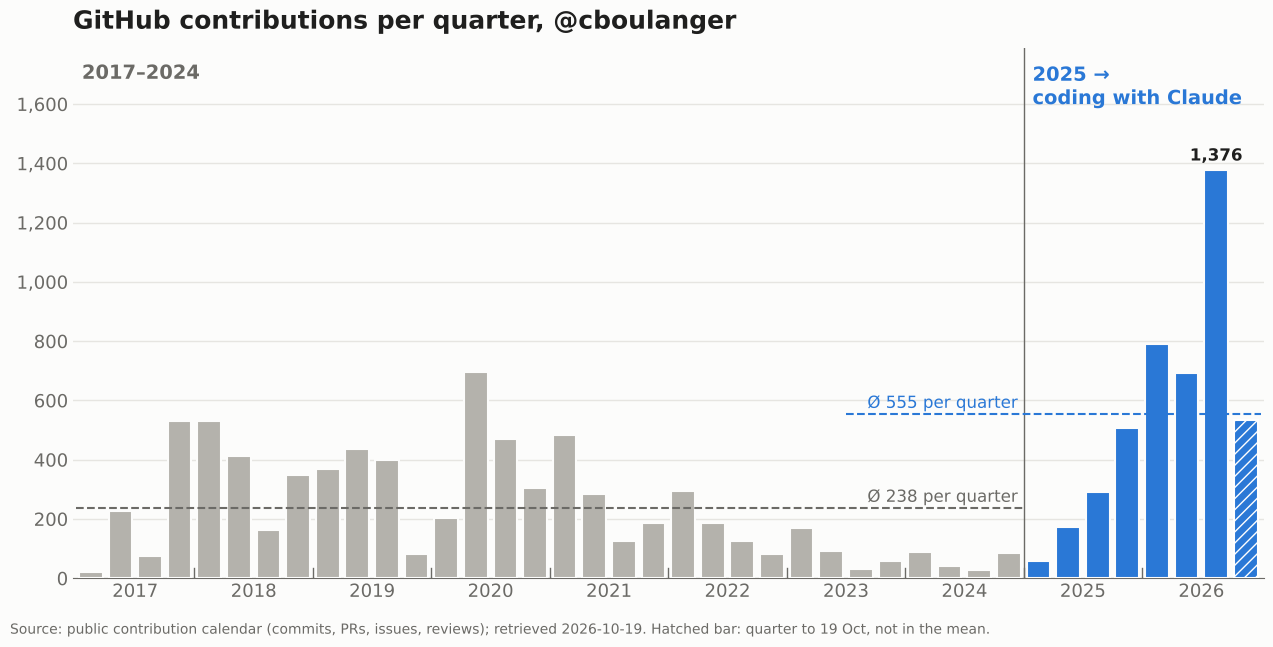

In [4]:
GRAY, BLUE, INK, MUTED, SURFACE = "#b4b2ac", "#2a78d6", "#1f1f1e", "#6b6a66", "#fcfcfb"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 13})

xs = list(range(len(rows))); counts = [n for _, _, n in rows]
split_x = next(i for i, (y, _, _) in enumerate(rows) if y >= SPLIT_YEAR)
fig, ax = plt.subplots(figsize=(13, 6.5), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
bars = ax.bar(xs, counts, width=0.8, color=[GRAY if i < split_x else BLUE for i in xs],
              edgecolor=SURFACE, linewidth=1.5, zorder=3)
if partial:
    bars[-1].set_hatch("///"); bars[-1].set_edgecolor("white")

# period means as dashed reference lines
ax.hlines(m_before, -.5, split_x - .5, color=MUTED, ls="--", lw=1.5, zorder=4)
ax.hlines(m_after, split_x - 6.5, xs[-1] + .5, color=BLUE, ls="--", lw=1.5, zorder=4)
ax.text(split_x - .7, m_before + 20, f"Ø {m_before:,} per quarter", ha="right", color=MUTED, fontsize=12)
ax.text(split_x - .7, m_after + 20, f"Ø {m_after:,} per quarter", ha="right", color=BLUE, fontsize=12)

# label the highest bar of the recent period
peak = max(range(split_x, len(rows)), key=lambda i: counts[i])
ax.text(peak, counts[peak] + 20, f"{counts[peak]:,}", ha="center", va="bottom", color=INK,
        fontsize=12, fontweight="bold")

ax.axvline(split_x - .5, color=MUTED, lw=1, zorder=2)
top = max(counts) * 1.3
ax.text(-.3, top * .97, f"{FIRST_YEAR}–{SPLIT_YEAR - 1}", color=MUTED, fontsize=14, fontweight="bold", va="top")
ax.text(split_x - .2, top * .97, f"{SPLIT_YEAR} →\ncoding with Claude", color=BLUE, fontsize=14, fontweight="bold", va="top", ha="left")

ax.set_ylim(0, top); ax.set_xlim(-.6, xs[-1] + .6)
year_starts = [i for i, (y, q, _) in enumerate(rows) if q == 1]
ax.set_xticks([i + 1.5 for i in year_starts]); ax.set_xticklabels([rows[i][0] for i in year_starts])
for i in year_starts[1:]:
    ax.axvline(i - .5, ymax=.02, color=MUTED, lw=1)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.grid(axis="y", color="#e6e5e1", lw=1, zorder=0)
for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(MUTED); ax.tick_params(colors=MUTED, length=0)
ax.set_title(f"GitHub {metric} per quarter, @{LOGIN}", loc="left", color=INK, fontsize=18, fontweight="bold", pad=14)
src = "public contribution calendar (commits, PRs, issues, reviews)" if metric == "contributions" else "GitHub GraphQL API, commit contributions incl. private"
fig.text(0.01, 0.01, f"Source: {src}; retrieved {retrieved:%Y-%m-%d}." + (f" Hatched bar: quarter to {retrieved:%d %b}, not in the mean." if partial else ""),
         color=MUTED, fontsize=10)
fig.tight_layout(rect=(0, 0.03, 1, 1))
for ext in ("svg", "png"):
    fig.savefig(f"commits-per-quarter.{ext}", dpi=200, facecolor=SURFACE)
plt.show()